# 04 — Random Forest para regressão do PIB

**Responsável:** Peter (João Pedro Amorim)

Entrada: `data/processed/base_modelagem.csv`. Saídas: `outputs/regressao_rf_2024.csv` e `outputs/metricas_rf_regressao.csv`.

Protocolo temporal:
1. **Escolha de hiperparâmetros**: treino com anos-alvo ≤ 2021, validação em 2022.
2. **Teste**: reajuste com anos-alvo ≤ 2022 e previsão de 2023, comparada ao PIB oficial (R² e MAPE).
3. **Entrega**: reajuste com anos-alvo ≤ 2023 e previsão de 2024.

In [1]:
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import preprocessamento as prep

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
FIG = root / "outputs/figuras"
FIG.mkdir(parents=True, exist_ok=True)

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.pipeline import Pipeline

SEED = 42
X_COLS = prep.FEATURES_NUMERICAS + prep.FEATURES_CATEGORICAS
base = pd.read_csv(root / "data/processed/base_modelagem.csv")
historico = base[base["conjunto"] == "historico"]
print(base.shape, len(X_COLS), "variáveis")

(23352, 26) 18 variáveis


## Formulação

O Random Forest não extrapola: só prevê valores dentro da faixa vista no treino. Como o PIB nominal cresce todo ano e vai de milhões a trilhões, o modelo **não** prevê o nível do PIB diretamente. O alvo é o crescimento logarítmico

$$y_t = \log(PIB_t / PIB_{t-1}),$$

e a previsão em nível é reconstruída como $\widehat{PIB}_t = PIB_{t-1} \cdot e^{\hat y_t}$. Assim, o modelo aprende *quanto* cada município cresce a partir do seu histórico, estrutura setorial, porte e contexto estadual, e o erro em log se alinha ao MAPE (erro relativo).

In [2]:
def criar_modelo(**params):
    return Pipeline([
        ("prep", prep.criar_preprocessador(escalonar=False)),
        ("rf", RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1, **params)),
    ])


def prever_pib(modelo, dados):
    return dados["pib_lag1_mil_reais"].to_numpy() * np.exp(modelo.predict(dados[X_COLS]))


def metricas(real, previsto):
    return {
        "R2": r2_score(real, previsto),
        "MAPE_%": 100 * mean_absolute_percentage_error(real, previsto),
        "erro_pct_mediano": 100 * np.median(np.abs(previsto / real - 1)),
    }

## 1. Escolha dos hiperparâmetros (validação em 2022)

In [3]:
treino, valid = historico[historico["ano"] <= 2021], historico[historico["ano"] == 2022]
resultados = []
for max_features in (0.33, 0.5, 1.0):
    for min_samples_leaf in (1, 5, 20):
        m = criar_modelo(max_features=max_features, min_samples_leaf=min_samples_leaf)
        m.fit(treino[X_COLS], treino["log_razao_pib"])
        resultados.append({"max_features": max_features, "min_samples_leaf": min_samples_leaf,
                           **metricas(valid["pib_mil_reais"], prever_pib(m, valid))})
grade = pd.DataFrame(resultados).sort_values("MAPE_%")
grade.round(4)

,max_features,min_samples_leaf,R2,MAPE_%,erro_pct_mediano
2,0.33,20,0.9882,9.2823,6.0100
5,0.50,20,0.9882,9.3291,6.0862
8,1.00,20,0.9863,9.4162,6.3010
1,0.33,5,0.9883,9.4972,6.0897
0,0.33,1,0.9873,9.5419,6.0133
4,0.50,5,0.9871,9.5606,6.2158
3,0.50,1,0.9869,9.6252,6.1628
7,1.00,5,0.9877,9.7102,6.3587
6,1.00,1,0.9879,9.7599,6.3322


In [4]:
melhor = grade.iloc[0]
PARAMS = {"max_features": float(melhor["max_features"]), "min_samples_leaf": int(melhor["min_samples_leaf"])}
PARAMS

{'max_features': 0.33, 'min_samples_leaf': 20}

Folhas maiores (`min_samples_leaf`) suavizam a previsão e reduzem o efeito dos saltos extremos de crescimento; sortear um terço das variáveis em cada divisão (`max_features`) diversifica as árvores. A escolha usa apenas 2022, sem olhar 2023.

## 2. Teste em 2023 (treino com anos-alvo até 2022)

In [5]:
treino, teste = historico[historico["ano"] <= 2022], historico[historico["ano"] == 2023]
rf_2023 = criar_modelo(**PARAMS).fit(treino[X_COLS], treino["log_razao_pib"])
pred_2023 = prever_pib(rf_2023, teste)

tabela = pd.DataFrame({
    "Ingênuo (PIB_2023 = PIB_2022)": metricas(teste["pib_mil_reais"], teste["pib_lag1_mil_reais"]),
    "Random Forest": metricas(teste["pib_mil_reais"], pred_2023),
}).T
tabela.round(6)

,R2,MAPE_%,erro_pct_mediano
Ingênuo (PIB_2023 = PIB_2022),0.987439,13.466130,12.108807
Random Forest,0.998480,8.997944,5.994356


Referência: a regressão linear ampliada da Lulu obteve, no mesmo teste de 2023, R² = 0,995463 e MAPE = 13,21%.

In [6]:
erros = teste.assign(pib_previsto=pred_2023, erro_pct=100 * (pred_2023 / teste["pib_mil_reais"] - 1))
print("MAPE por UF (%):")
print(erros.groupby("uf")["erro_pct"].apply(lambda e: e.abs().mean()).round(2))
erros["porte"] = pd.qcut(erros["pib_lag1_mil_reais"], 4, labels=["Q1 menor", "Q2", "Q3", "Q4 maior"])
print("\nMAPE por quartil de porte (%):")
print(erros.groupby("porte", observed=True)["erro_pct"].apply(lambda e: e.abs().mean()).round(2))
print("\nFração com erro absoluto <= 10%:", round((erros["erro_pct"].abs() <= 10).mean() * 100, 1))
erros.reindex(erros["erro_pct"].abs().sort_values(ascending=False).index)[
    ["municipio", "uf", "pib_lag1_mil_reais", "pib_mil_reais", "pib_previsto", "erro_pct"]].head(8).round(1)

MAPE por UF (%):
uf
ES     7.77
MG     8.06
RJ     8.21
SP    10.49
Name: erro_pct, dtype: float64

MAPE por quartil de porte (%):
porte
Q1 menor     8.12
Q2          11.06
Q3           8.98
Q4 maior     7.83
Name: erro_pct, dtype: float64

Fração com erro absoluto <= 10%: 68.0


,municipio,uf,pib_lag1_mil_reais,pib_mil_reais,pib_previsto,erro_pct
194,Albertina,MG,176971.6,90906.2,200826.5,120.9
4562,Guaxupé,MG,3912373.2,2431559.6,4468009.1,83.8
17582,Ilhabela,SP,24913501.4,14830714.9,24531236.9,65.4
4898,Indianópolis,MG,861720.5,2150116.6,824396.7,-61.7
22804,Tejupá,SP,124784.1,341127.4,132273.0,-61.2
14866,Arco-Íris,SP,62022.3,136328.5,65546.6,-51.9
2756,Confins,MG,780843.1,1617016.9,816008.9,-49.5
13900,Quissamã,RJ,8493476.2,5669644.0,8471251.9,49.4


In [7]:
importancias = pd.Series(
    rf_2023.named_steps["rf"].feature_importances_,
    index=rf_2023.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False)
importancias.head(12).round(4)

cresc_pib_lag1                  0.1775
cresc_pib_mediana_uf_lag1       0.1472
part_industria_ult              0.1051
part_agro_ult                   0.0968
part_servicos_ult               0.0880
cresc_pib_lag2                  0.0561
log_pib_per_capita_lag1         0.0552
log_producao_agricola_lag1      0.0527
log_pib_lag1                    0.0359
log_pib_lag2                    0.0326
cresc_producao_agricola_lag1    0.0324
log_populacao_ult               0.0320
dtype: float64

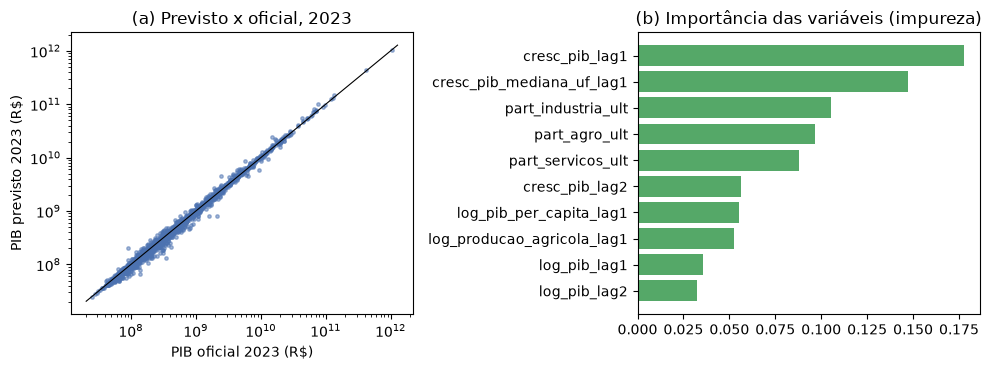

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.scatter(teste["pib_mil_reais"] * 1000, pred_2023 * 1000, s=6, alpha=0.5, color="#4C72B0")
lim = [teste["pib_mil_reais"].min() * 800, teste["pib_mil_reais"].max() * 1200]
ax.plot(lim, lim, color="black", lw=0.8)
ax.set(xscale="log", yscale="log", xlabel="PIB oficial 2023 (R$)", ylabel="PIB previsto 2023 (R$)",
       title="(a) Previsto x oficial, 2023")
top = importancias.head(10)[::-1]
axes[1].barh(top.index, top.values, color="#55A868")
axes[1].set_title("(b) Importância das variáveis (impureza)")
fig.tight_layout()
fig.savefig(FIG / "fig_rf_regressao_2023.png", dpi=200)
plt.show()

## 3. Previsão de 2024 (treino com anos-alvo até 2023)

In [9]:
prev = base[base["conjunto"] == "previsao"]
rf_final = criar_modelo(**PARAMS).fit(historico[X_COLS], historico["log_razao_pib"])
pib_2024 = prever_pib(rf_final, prev)

saida = pd.DataFrame({"codigo_municipio": prev["codigo_municipio"].to_numpy(), "ano": 2024,
                      "pib_previsto_mil_reais": np.round(pib_2024, 3)})
assert len(saida) == 1668 and saida["codigo_municipio"].is_unique
assert np.isfinite(saida["pib_previsto_mil_reais"]).all() and (saida["pib_previsto_mil_reais"] > 0).all()
saida.to_csv(root / "outputs/regressao_rf_2024.csv", index=False, encoding="utf-8")

var_2024 = 100 * (pib_2024 / prev["pib_lag1_mil_reais"].to_numpy() - 1)
print("Variação prevista 2024 x 2023 (%):")
print(pd.Series(var_2024).describe().round(2))
print("\nPIB total previsto do Sudeste 2024 (R$ tri):", round(pib_2024.sum() / 1e9, 3),
      "| 2023 oficial:", round(prev["pib_lag1_mil_reais"].sum() / 1e9, 3))
saida.head()

Variação prevista 2024 x 2023 (%):
count    1668.00
mean       13.88
std         4.68
min       -20.68
25%        11.77
50%        14.56
75%        16.64
max        28.75
dtype: float64

PIB total previsto do Sudeste 2024 (R$ tri): 6.32 | 2023 oficial: 5.799


,codigo_municipio,ano,pib_previsto_mil_reais
0,3100104,2024,229124.592
1,3100203,2024,742237.916
2,3100302,2024,382078.903
3,3100401,2024,97690.186
4,3100500,2024,197513.791


In [10]:
metricas_csv = tabela.reset_index(names="modelo").assign(ano_teste=2023, **{k: str(v) for k, v in PARAMS.items()})
metricas_csv.to_csv(root / "outputs/metricas_rf_regressao.csv", index=False, encoding="utf-8")
metricas_csv.round(6)

,modelo,R2,MAPE_%,erro_pct_mediano,ano_teste,max_features,min_samples_leaf
0,Ingênuo (PIB_2023 = PIB_2022),0.987439,13.466130,12.108807,2023,0.33,20
1,Random Forest,0.998480,8.997944,5.994356,2023,0.33,20


In [11]:
# Comparação com a previsão de 2024 da regressão linear (arquivo da Lulu, apenas leitura).
lin = pd.read_csv(root / "outputs/regressao_linear_2024_selecionada.csv")
comp = saida.merge(lin, on=["codigo_municipio", "ano"], suffixes=("_rf", "_linear"))
dif = 100 * (comp["pib_previsto_mil_reais_rf"] / comp["pib_previsto_mil_reais_linear"] - 1)
print(len(comp), "municípios em comum; diferença RF x linear (%):")
dif.describe().round(2)

1668 municípios em comum; diferença RF x linear (%):


count    1668.00
mean       -8.66
std        13.56
min       -61.59
25%       -16.59
50%        -3.71
75%         1.92
max        10.67
dtype: float64